# Риск-аверсия, политика и чувствительность стоимости

Сравниваем сохранённые **стационарные** модели при одной и той же $\eta$ и разных $\bar\gamma$. $\bar\gamma$ — коэффициент рекурсивного энтропийного риска на единицу книги; в деньгах $\gamma_t=\bar\gamma/L_t$. Шок здесь мгновенный: начальная ставка $r$ повышается на 100 б.п., долгосрочные средние под $P$ и $Q$ остаются прежними.

Сначала сравниваем политики и $\Delta V$ **в одинаковых состояниях**, затем — результаты их деятельности на общих случайных траекториях. Это разные вопросы: различие правил управления и различие распределений баланса. После этого можно включить долгую независимую оценку каждой политики $\widehat\pi_{\bar\gamma}$ при её собственной риск-аверсии и при нулевой. Эта оценка не переобучает управление.

Текущий срез — `stationary_gamma_eta_chi5`, $\chi=5$, $\eta=0.01$. Старая сетка `stationary_gamma_eta` использовала $\chi=0$ и должна рассматриваться отдельно. Ноутбук проверяет, что внутри выбранного среза остальные параметры среды совпадают.

In [1]:
from pathlib import Path
from dataclasses import asdict, replace
from copy import deepcopy
import hashlib, json, os, sys
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

SWEEP_DIR = 'runs/stationary_gamma_eta_chi5'
ETA = 0.01
GAMMAS = None                    # None: все доступные; например [0, 10, 20]
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
DTYPE = torch.float64
SMOKE = bool(os.environ.get('IRRBB_NOTEBOOK_SMOKE'))
GRID_N = 9 if SMOKE else 31
PATHS = 8 if SMOKE else 64
YEARS = 2.0 if SMOKE else 15.0
PATH_SEED = 1977
SHOCK = .01
# Новые долгие оценки включаются явно. Существующий кеш читается при False.
RUN_FULL_EVALUATION = False
RESUME_UNCONVERGED = False        # True: продолжать несошедшийся кеш до EVAL_ITERATIONS
EVAL_ITERATIONS = 2 if SMOKE else 1000  # общий лимит с учётом уже выполненных итераций
EVAL_TOL = .005
EVAL_TRAIN = 64 if SMOKE else 2048
EVAL_VALID = 32 if SMOKE else 512
EVAL_EPOCHS = 2 if SMOKE else 20
EVAL_SEED = 1943

root=next((q for q in (Path.cwd(),*Path.cwd().parents)
           if (q/'continuous_time_irrbb/risk_sensitive/stationary_solver.py').exists()),None)
if root is None:raise FileNotFoundError('Запустите Jupyter внутри проекта IRRBB')
sys.path.insert(0,str(root))
from continuous_time_irrbb.risk_sensitive.stationary_solver import (
    StationarySolution, generate_stationary_cloud, make_operator,
    fit_projection, stationary_continuation)
if DEVICE=='cpu':torch.set_num_threads(min(torch.get_num_threads(),4))
plt.style.use('seaborn-v0_8-whitegrid')
sweep_dir=Path(SWEEP_DIR).expanduser()
if not sweep_dir.is_absolute():sweep_dir=root/'continuous_time_irrbb/risk_sensitive'/sweep_dir
records=[]
# Только непосредственные точки sweep: вложенные permanent_shock_cache — другие задачи.
for path in sorted(sweep_dir.glob('*/stationary_solution.pt')):
    if 'gamma_interpretation_cache' in path.parts:continue
    payload=torch.load(path,map_location='cpu',weights_only=True)
    eta=payload['parameters'].get('floating_demand_slope',0.)
    gamma=payload['stationary_config']['risk_aversion_per_loan']
    if not np.isclose(eta,ETA,atol=1e-12,rtol=0):continue
    if GAMMAS is not None and not any(np.isclose(gamma,g) for g in GAMMAS):continue
    model=StationarySolution.load(path,device=DEVICE,dtype=DTYPE)
    report_path=path.with_name('report.json')
    report=json.loads(report_path.read_text()) if report_path.exists() else {}
    records.append({'gamma':float(gamma),'model':model,'path':path,
                    'sha':hashlib.sha256(path.read_bytes()).hexdigest(),
                    'report':report,'diagnostics':payload.get('diagnostics',[])})
records.sort(key=lambda q:q['gamma'])
if len(records)<2:raise ValueError(f'Нужно хотя бы две gamma при eta={ETA}; найдено {len(records)}')
if len({q['gamma'] for q in records})!=len(records):raise ValueError('Повторные gamma: выберите одну сетку')
environment_parameters=[asdict(q['model'].environment.p) for q in records]
if any(p!=environment_parameters[0] for p in environment_parameters[1:]):
    raise ValueError('Кроме gamma меняются параметры среды; сравнение смешивает эффекты')
if len({q['model'].config.dt for q in records})!=1:raise ValueError('Разные временные шаги')
env=records[0]['model'].environment
p=env.p
dt=records[0]['model'].config.dt
gammas=np.array([q['gamma'] for q in records])
colors={q['gamma']:plt.cm.tab10(i%10) for i,q in enumerate(records)}
print(f'eta={ETA:g}; gamma_bar={gammas.tolist()}; device={DEVICE}; dt={dt:g}')
print(f'chi={p.growth_rate_sensitivity:g}; g0={p.loan_growth:g}; alpha={p.dividend_fraction:g}; '
      f'L0={p.loans:g}; sF={p.fixed_spread:g}; sV0={p.floating_spread_0:g}')
print('gamma     RMSE сохранённой сети   converged     run')
for q in records:
    last=q['diagnostics'][-1] if q['diagnostics'] else {}
    print(f"{q['gamma']:5g}      {last.get('bellman_rmse',float('nan')):.6f}        {q['report'].get('converged_on_validation_cloud')}       {q['path'].parent.name}")

eta=0.01; gamma_bar=[0.0, 5.0, 10.0, 20.0]; device=cpu; dt=0.25
chi=5; g0=0.05; alpha=0.9; L0=100; sF=0.015; sV0=0.015
gamma     RMSE сохранённой сети   converged     run
    0      0.019395        False       g0_e0.01
    5      0.006984        False       g5_e0.01
   10      0.007385        False       g10_e0.01
   20      0.010724        False       g20_e0.01


## Политика и $\Delta V$ в одной и той же книге

Для всех моделей одинаковы $L_0=100$, исходная ставка 8%, капитал 12% книги и доля fixed 50%. Старый fixed-купон берётся из общей среды при 8%, старый float-спред — по общей формуле при исходной доле float 50%. В остальных сценариях меняем только явно названные компоненты. Сохранённые сети используются как приближения $V_{\bar\gamma}$; малая невязка на обучающем облаке не гарантирует точность производной по ставке.

Рост $\bar\gamma$ усиливает неприятие неопределённости будущих выплат, но не задаёт заранее знак изменения $f$ или $\Delta V$. $f$ — доля fixed **в новой выдаче**. При точных решениях стоимость одного и того же потока не растёт от усиления риск-аверсии; между приближёнными оптимальными сетями возможны численные нарушения этого порядка.

gamma     f0        V0         ΔV0       ΔV0/V0,%
    0    0.9688    242.6862    -11.5239      -4.748
    5    0.3438    106.6505     -4.3535      -4.082
   10    0.0625     88.9396     -3.3754      -3.795
   20    0.0000     75.2326     -2.6455      -3.516


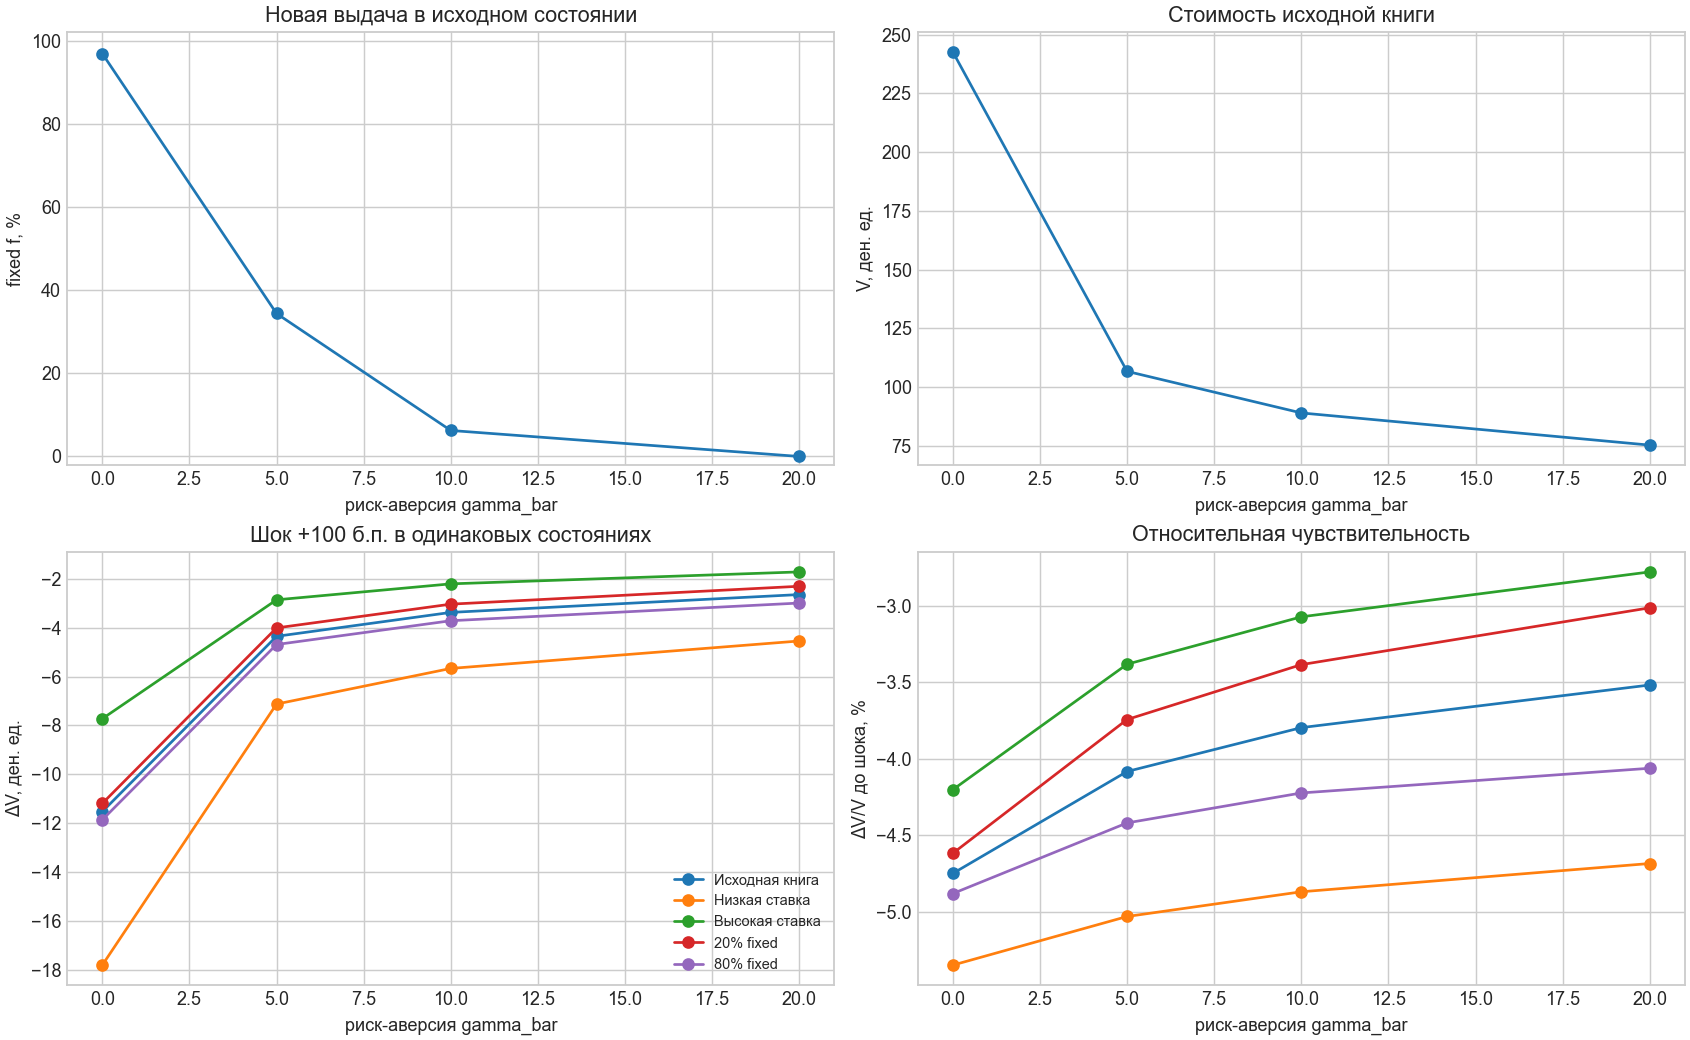

In [3]:
OLD_COUPON=float(env.new_fixed_coupon(torch.tensor(.08,device=DEVICE,dtype=DTYPE)))
OLD_FLOAT=p.floating_spread_0-p.floating_demand_slope*.5
specs=[('Исходная книга',.08,.5,.12),
       ('Низкая ставка',.02,.5,.12),('Высокая ставка',.14,.5,.12),
       ('20% fixed',.08,.2,.12),('80% fixed',.08,.8,.12),
       ('Пониженный капитал',.08,.5,.105),
       ('Вся книга float',.08,0.,.12),('Вся книга fixed',.08,1.,.12)]
def states_for(rates,shares,car=.12):
    rates,shares=np.broadcast_arrays(rates,shares)
    fixed=p.loans*shares
    yy=OLD_COUPON*fixed+OLD_FLOAT*(p.loans-fixed)
    return torch.as_tensor(np.stack((rates,fixed,yy,np.full_like(rates,car*p.loans)),axis=-1),
                           device=DEVICE,dtype=DTYPE)
states=torch.cat([states_for(np.array([r]),np.array([a]),e) for _,r,a,e in specs])
bump=torch.tensor([SHOCK,0,0,0],device=DEVICE,dtype=DTYPE)
anchors=torch.cat((states,states+bump))
N_SC=len(specs)
with torch.no_grad():
    mtm_values=env.terminal_value(anchors).cpu().numpy()
mtm_delta=mtm_values[N_SC:]-mtm_values[:N_SC]
@torch.no_grad()
def actions_in_batches(model,x,loans=None):
    if loans is None:
        return torch.cat([model.action(part,action_count=model.config.action_count) for part in x.split(128)])
    return torch.cat([model.action(part,loans=ll,action_count=model.config.action_count)
                      for part,ll in zip(x.split(128),loans.split(128))])
for q in records:
    with torch.no_grad():
        q['source_values']=q['model'].value(anchors).cpu().numpy()
        q['delta_v']=q['source_values'][N_SC:]-q['source_values'][:N_SC]
        q['f_reference']=float(actions_in_batches(q['model'],states[:1])[0])
print('gamma     f0        V0         ΔV0       ΔV0/V0,%')
for q in records:
    print(f"{q['gamma']:5g}  {q['f_reference']:8.4f}  {q['source_values'][0]:10.4f}  "
          f"{q['delta_v'][0]:10.4f}  {100*q['delta_v'][0]/q['source_values'][0]:10.3f}")
fig,axes=plt.subplots(2,2,figsize=(13,8),constrained_layout=True)
axes[0,0].plot(gammas,[100*q['f_reference'] for q in records],marker='o')
axes[0,0].set(title='Новая выдача в исходном состоянии',ylabel='fixed f, %',ylim=(-2,102))
axes[0,1].plot(gammas,[q['source_values'][0] for q in records],marker='o')
axes[0,1].set(title='Стоимость исходной книги',ylabel='V, ден. ед.')
for i in (0,1,2,3,4):
    axes[1,0].plot(gammas,[q['delta_v'][i] for q in records],marker='o',label=specs[i][0])
    axes[1,1].plot(gammas,[100*q['delta_v'][i]/q['source_values'][i] for q in records],
                   marker='o',label=specs[i][0])
axes[1,0].set(title='Шок +100 б.п. в одинаковых состояниях',ylabel='ΔV, ден. ед.')
axes[1,1].set(title='Относительная чувствительность',ylabel='ΔV/V до шока, %')
for ax in axes.flat:ax.set_xlabel('риск-аверсия gamma_bar')
axes[1,0].legend(fontsize=8);plt.show()

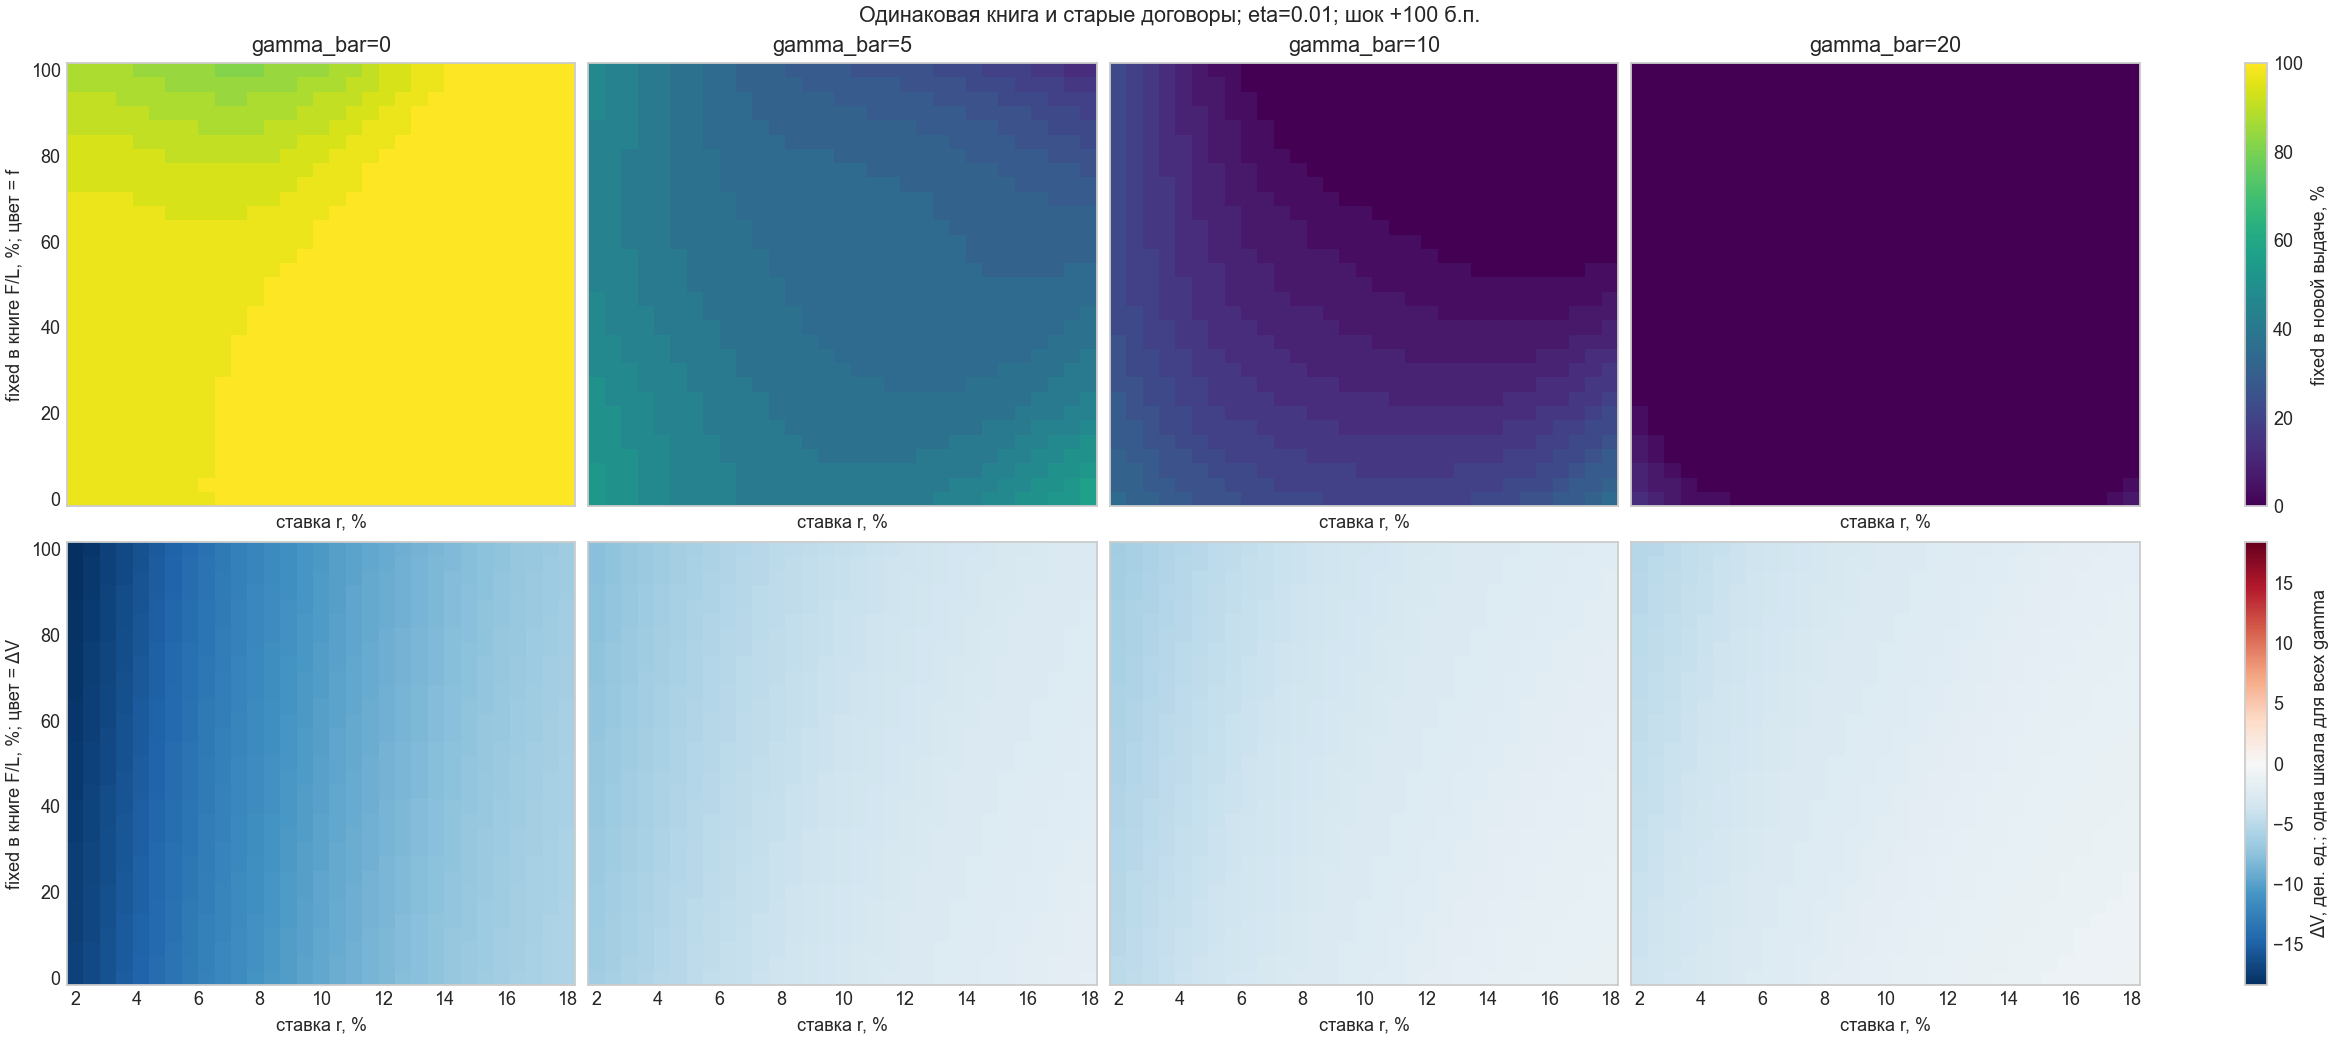

In [4]:
rate_axis=np.linspace(.02,.18,GRID_N)
share_axis=np.linspace(0,1,GRID_N)
rate_mesh,share_mesh=np.meshgrid(rate_axis,share_axis,indexing='xy')
grid_states=states_for(rate_mesh,share_mesh).reshape(-1,4)
fig,axes=plt.subplots(2,len(records),figsize=(4.5*len(records),8),
                       sharex=True,sharey=True,squeeze=False,constrained_layout=True)
maps=[]
for q in records:
    with torch.no_grad():
        f=actions_in_batches(q['model'],grid_states).cpu().numpy().reshape(rate_mesh.shape)
        dv=(q['model'].value(grid_states+bump)-q['model'].value(grid_states)).cpu().numpy().reshape(rate_mesh.shape)
    maps.append((f,dv))
limit=max(float(np.max(np.abs(dv))) for _,dv in maps)
limit=max(limit,.001)
for j,(q,(f,dv)) in enumerate(zip(records,maps)):
    top=axes[0,j].pcolormesh(100*rate_mesh,100*share_mesh,100*f,vmin=0,vmax=100,cmap='viridis',shading='auto')
    bottom=axes[1,j].pcolormesh(100*rate_mesh,100*share_mesh,dv,
                 norm=TwoSlopeNorm(vmin=-limit,vcenter=0,vmax=limit),cmap='RdBu_r',shading='auto')
    axes[0,j].set_title(f"gamma_bar={q['gamma']:g}")
    for ax in axes[:,j]:ax.set_xlabel('ставка r, %')
axes[0,0].set_ylabel('fixed в книге F/L, %; цвет = f')
axes[1,0].set_ylabel('fixed в книге F/L, %; цвет = ΔV')
fig.colorbar(top,ax=axes[0,:],label='fixed в новой выдаче, %')
fig.colorbar(bottom,ax=axes[1,:],label='ΔV, ден. ед.; одна шкала для всех gamma')
fig.suptitle(f'Одинаковая книга и старые договоры; eta={ETA:g}; шок +100 б.п.')
plt.show()

## Деятельность банков на одинаковых траекториях ставки

Все политики стартуют из одной книги и получают одни и те же нормальные приращения ставки. Каждая действует по своему текущему состоянию. Линии — среднее по путям, полосы — 10–90-й перцентили, а не доверительные интервалы. Ставка и $L_t$ одинаковы между политиками в данной модели; $F_t,Y_t,E_t$ могут различаться.

Показываем состав выдачи, структуру накопленной книги, модельный CAR, накопленные дисконтированные выплаты владельцу и текущую $\Delta V/L_t$. Последняя величина пересчитывается локальным мгновенным шоком в каждом посещённом состоянии. Здесь различия отражают **и** политику, **и** состояние, которое она создала; предыдущие карты сравнивали строго одинаковые состояния.

Распределение выплат за показанный конечный горизонт — общий денежный показатель для всех политик. Его среднее и нижний дециль не совпадают с рекурсивным энтропийным функционалом $J_\gamma$ и не учитывают остаточный капитал и последующие выплаты.

симуляция gamma= 0.0
симуляция gamma= 5.0
симуляция gamma= 10.0
симуляция gamma= 20.0
gamma=0: средняя PV=63.787, 10-й перцентиль=52.881, SE среднего=1.317
gamma=5: средняя PV=60.360, 10-й перцентиль=51.794, SE среднего=0.921
gamma=10: средняя PV=57.143, 10-й перцентиль=50.161, SE среднего=0.747
gamma=20: средняя PV=54.597, 10-й перцентиль=48.249, SE среднего=0.659


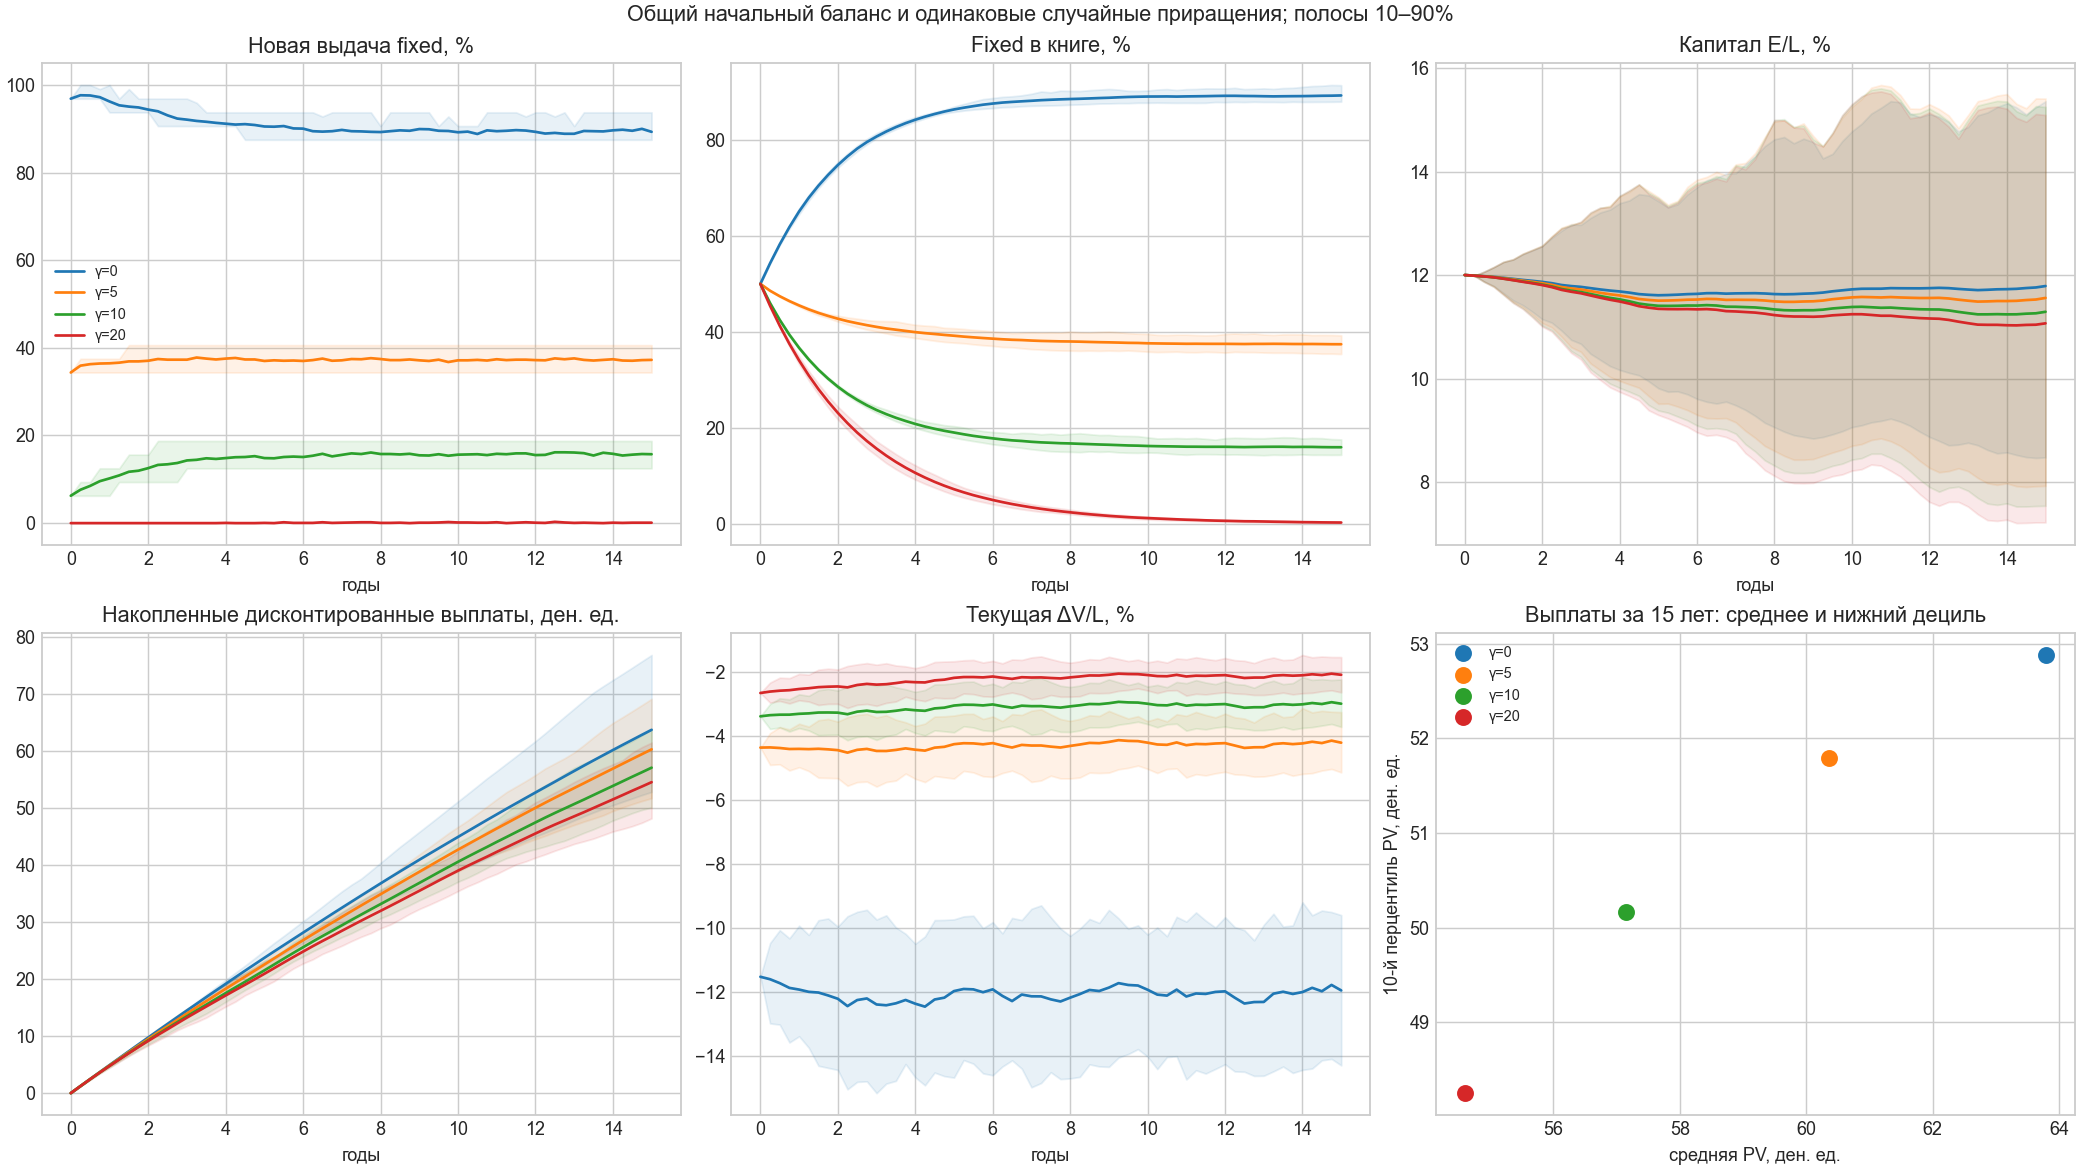

In [6]:
@torch.no_grad()
def simulate_policy(q):
    steps=round(YEARS/dt)
    gen=torch.Generator(device='cpu').manual_seed(PATH_SEED)
    noises=torch.randn(steps,PATHS,generator=gen,dtype=DTYPE).to(DEVICE)
    model=q['model'];sim_env=model.environment
    x=states[0].expand(PATHS,-1).clone()
    loans=torch.full((PATHS,),p.loans,device=DEVICE,dtype=DTYPE)
    discount=torch.ones_like(loans);pv=torch.zeros_like(loans)
    history={k:[] for k in ('f','fixed','car','pv','dv')}
    for k in range(steps+1):
        action=actions_in_batches(model,x,loans)
        dv=(model.value(x+bump,loans=loans)-model.value(x,loans=loans))/loans*100
        for name,v in (('f',100*action),('fixed',100*x[:,1]/loans),
                       ('car',100*x[:,3]/loans),('pv',pv),('dv',dv)):
            history[name].append(v.cpu().numpy().copy())
        if k==steps:break
        step=sim_env.step(x,action,noises[k],dt,time=k*dt,loans=loans,validate=False)
        pv=pv+discount*step.dividend_pv
        discount=discount*step.discount
        x,loans=step.state,step.next_loans
    return np.arange(steps+1)*dt,{name:np.stack(v) for name,v in history.items()}

trajectories={}
for q in records:
    print('симуляция gamma=',q['gamma'],flush=True)
    trajectories[q['gamma']]=simulate_policy(q)
fig,axes=plt.subplots(2,3,figsize=(16,9),constrained_layout=True)
settings=(('f','Новая выдача fixed, %'),('fixed','Fixed в книге, %'),('car','Капитал E/L, %'),
          ('pv','Накопленные дисконтированные выплаты, ден. ед.'),('dv','Текущая ΔV/L, %'))
for q in records:
    t,hist=trajectories[q['gamma']];color=colors[q['gamma']]
    for ax,(name,title) in zip(axes.flat,settings):
        data=hist[name];lo,hi=np.quantile(data,[.1,.9],axis=1)
        ax.plot(t,data.mean(axis=1),color=color,label=f"γ={q['gamma']:g}")
        ax.fill_between(t,lo,hi,color=color,alpha=.10)
        ax.set(title=title,xlabel='годы')
    payoff=hist['pv'][-1]
    axes[1,2].scatter(payoff.mean(),np.quantile(payoff,.1),color=color,s=70,label=f"γ={q['gamma']:g}")
    print(f"gamma={q['gamma']:g}: средняя PV={payoff.mean():.3f}, "
          f"10-й перцентиль={np.quantile(payoff,.1):.3f}, SE среднего={payoff.std(ddof=1)/np.sqrt(PATHS):.3f}")
axes[1,2].set(title=f'Выплаты за {YEARS:g} лет: среднее и нижний дециль',
              xlabel='средняя PV, ден. ед.',ylabel='10-й перцентиль PV, ден. ед.')
axes[0,0].legend(fontsize=8);axes[1,2].legend(fontsize=8)
fig.suptitle('Общий начальный баланс и одинаковые случайные приращения; полосы 10–90%')
plt.show()

## Оценка одной политики при двух значениях риск-аверсии

Обозначим сохранённую политику модели с параметром $\bar\gamma$ через $\widehat\pi_{\bar\gamma}$. Для неё оцениваем $J_\gamma^{\widehat\pi_{\bar\gamma}}$ и $J_0^{\widehat\pi_{\bar\gamma}}$ через **оператор фиксированной политики без максимума**. Во время обеих оценок действия определяются исходным чекпоинтом, а не обновляемой оценочной сетью.

Разность $R_{\bar\gamma}(x)=J_\gamma^{\widehat\pi_{\bar\gamma}}(x)-J_0^{\widehat\pi_{\bar\gamma}}(x)$ — уровень поправки за риск при одной и той же политике. Для точных оценок $R\leq0$. Её **изменение при шоке** $\Delta R=R(x^+)-R(x)$ может иметь любой знак. В обоих случаях $\pi$ зависит от $\bar\gamma$: график не изолирует влияние коэффициента на одну общую для всей сетки политику.

Используем четыре члена, без произвольного бейзлайна:

$$\Delta\widehat V_{\bar\gamma}=\Delta MtM+\Delta(J_0^{\widehat\pi_{\bar\gamma}}-MtM)+\Delta R_{\bar\gamma}+\Delta(\widehat V_{\bar\gamma}-J_\gamma^{\widehat\pi_{\bar\gamma}}).$$

Для нового расчёта установите `RUN_FULL_EVALUATION=True` в первой ячейке. При четырёх gamma нужны **семь** оценок: для gamma=0 две задачи совпадают и выполняются один раз. Каждая может потребовать до `EVAL_ITERATIONS=1000` итераций; GPU рекомендуется. Прогресс сохраняется каждые 50 итераций. Повторный запуск читает кеш без обучения, даже если оценка не сошлась. Для явного продолжения увеличьте общий лимит и включите `RUN_FULL_EVALUATION=True`, `RESUME_UNCONVERGED=True`. Веса исходных политик не меняются. Диагностика включает невязку на независимом облаке, невязку в сценариях и дрейф оценок.

In [8]:
CACHE_ROOT=(Path('/private/tmp/irrbb_gamma_analysis_smoke') if SMOKE
            else sweep_dir/'gamma_interpretation_cache')

def evaluation_identity(q,gamma_eval):
    # Budget and stopping tolerance do not change the problem or state cloud;
    # excluding them allows an explicit resume with a larger iteration budget.
    ec=replace(q['model'].config,train_states=EVAL_TRAIN,validation_states=EVAL_VALID,
               iterations=EVAL_ITERATIONS,epochs_per_iteration=EVAL_EPOCHS,
               residual_tolerance=EVAL_TOL,learning_rate=.0005,
               seed=EVAL_SEED,risk_aversion_per_loan=gamma_eval)
    config_key=asdict(ec)
    for key in ('iterations','residual_tolerance'):config_key.pop(key)
    settings={'version':1,'source':q['sha'],'anchors':anchors.cpu().tolist(),
              'config':config_key,'dtype':str(DTYPE),
              'policy_action_count':q['model'].config.action_count}
    key=hashlib.sha256(json.dumps(settings,sort_keys=True).encode()).hexdigest()[:20]
    return ec,settings,CACHE_ROOT/f'eval_{key}.pt'

cloud_cache={}
def common_evaluation_clouds(ec):
    key=(ec.train_states,ec.validation_states,ec.exploration_steps,ec.seed)
    if key in cloud_cache:return cloud_cache[key]
    def cloud(n,seed,include):
        broad=generate_stationary_cloud(env,n//2,seed,ec.exploration_steps,
                                        device=torch.device(DEVICE),dtype=DTYPE)
        gen=torch.Generator(device='cpu').manual_seed(seed+99)
        local_n=n-len(broad)
        ids=torch.randint(len(anchors),(local_n,),generator=gen).to(DEVICE)
        jitter=torch.randn(local_n,4,generator=gen,dtype=DTYPE).to(DEVICE)
        scale=torch.tensor([.012,.08*p.loans,.01*p.loans,.025*p.loans],device=DEVICE,dtype=DTYPE)
        local=anchors[ids]+jitter*scale
        local[:,0].clamp_(min=0);local[:,1].clamp_(0,p.loans);local[:,2].clamp_(min=0)
        if include and local_n>=len(anchors):local[:len(anchors)]=anchors
        return torch.cat((broad,local))
    cloud_cache[key]=(cloud(ec.train_states,ec.seed+1,True),cloud(ec.validation_states,ec.seed+2,False))
    return cloud_cache[key]

@torch.no_grad()
def fixed_targets(operator,x,action,continuation,ec):
    return torch.cat([operator.evaluate(0,part,act,ec.dt,continuation)
                      for part,act in zip(x.split(ec.target_batch),action.split(ec.target_batch))])

def evaluate_gamma_policy(q,gamma_eval):
    ec,identity,path=evaluation_identity(q,gamma_eval)
    cached=torch.load(path,map_location='cpu',weights_only=True) if path.exists() else None
    if cached is None and CACHE_ROOT.exists():
        # CPU/GPU quadrature can differ at ~1e-12 in anchors; do not refit for that.
        expected={k:v for k,v in identity.items() if k!='anchors'}
        compatible=[]
        for candidate in CACHE_ROOT.glob('eval_*.pt'):
            item=torch.load(candidate,map_location='cpu',weights_only=True)
            old_identity=item.get('identity',{})
            old_settings={k:v for k,v in old_identity.items() if k!='anchors'}
            a=np.asarray(old_identity.get('anchors',[]),dtype=float)
            b=np.asarray(identity['anchors'],dtype=float)
            if old_settings==expected and a.shape==b.shape and np.allclose(a,b,rtol=0,atol=1e-10):
                compatible.append(item)
        if compatible:
            compatible.sort(key=lambda q:(not q['converged'],-q['diagnostics'][-1]['iteration'],
                                           q['diagnostics'][-1]['rmse']))
            cached=compatible[0]
    if cached is not None:
        can_resume=(RUN_FULL_EVALUATION and RESUME_UNCONVERGED and not cached['converged']
                    and cached['diagnostics'][-1]['iteration']<EVAL_ITERATIONS)
        if not can_resume:
            print('кеш:',q['gamma'],'оценка при',gamma_eval,flush=True)
            return cached
    elif not RUN_FULL_EVALUATION:
        print(f"Нет оценки π(gamma={q['gamma']:g}) при gamma={gamma_eval:g}; "
              'включите RUN_FULL_EVALUATION=True для вычисления.')
        return None
    model=q['model'];train_x,valid_x=common_evaluation_clouds(ec)
    train_a=actions_in_batches(model,train_x);valid_a=actions_in_batches(model,valid_x)
    anchor_a=actions_in_batches(model,anchors)
    operator=make_operator(model.environment,ec,anchors)
    net=deepcopy(model.value_net)
    diagnostics=[];start=0
    if cached is not None:
        net.load_state_dict(cached['network'])
        diagnostics=cached['diagnostics'];start=diagnostics[-1]['iteration']
    stable=0;converged=False
    def snapshot():
        with torch.no_grad():vals=net(anchors).cpu()
        return {'gamma_policy':q['gamma'],'gamma_eval':gamma_eval,'anchors':vals,
                'network':{k:v.detach().cpu() for k,v in net.state_dict().items()},
                'diagnostics':diagnostics,'converged':converged,'identity':identity}
    for iteration in range(start+1,EVAL_ITERATIONS+1):
        torch.manual_seed(EVAL_SEED+iteration)
        cont=stationary_continuation(model.environment,net)
        train_y=fixed_targets(operator,train_x,train_a,cont,ec)
        valid_y=fixed_targets(operator,valid_x,valid_a,cont,ec)
        new_net,fit=fit_projection(net,train_x,train_y,valid_x,valid_y,ec)
        new_cont=stationary_continuation(model.environment,new_net)
        with torch.no_grad():
            res=new_net(valid_x)-fixed_targets(operator,valid_x,valid_a,new_cont,ec)
            ar=new_net(anchors)-operator.evaluate(0,anchors,anchor_a,ec.dt,new_cont)
            drift=(new_net(anchors)-net(anchors)).abs().max().item()
            info={'iteration':iteration,'rmse':res.square().mean().sqrt().item(),
                  'q95':torch.quantile(res.abs(),.95).item(),'anchor':ar.abs().max().item(),
                  'drift':drift,'projection_rmse':fit['projection_rmse']}
        diagnostics.append(info);net=new_net
        good=(info['rmse']<=EVAL_TOL and info['q95']<=3*EVAL_TOL
              and info['anchor']<=EVAL_TOL and info['drift']<=EVAL_TOL)
        stable=stable+1 if good else 0
        converged=stable>=5
        if iteration==start+1 or iteration%50==0 or converged or iteration==EVAL_ITERATIONS:
            print(f"π gamma={q['gamma']:g}, оценка gamma={gamma_eval:g}, iter={iteration}: "
                  f"RMSE={info['rmse']:.5f}, anchor={info['anchor']:.5f}, drift={drift:.5f}",flush=True)
        if iteration%50==0 or converged or iteration==EVAL_ITERATIONS:
            path.parent.mkdir(parents=True,exist_ok=True)
            temporary=path.with_suffix('.tmp')
            torch.save(snapshot(),temporary);temporary.replace(path)
        if converged:break
    return snapshot()

evaluations={}
for q in records:
    zero=evaluate_gamma_policy(q,0.)
    risk=zero if q['gamma']==0 else evaluate_gamma_policy(q,q['gamma'])
    if zero is not None and risk is not None:
        evaluations[q['gamma']]=(zero,risk)
print(f'Полностью оценено политик: {len(evaluations)} из {len(records)}')

кеш: 0.0 оценка при 0.0
кеш: 5.0 оценка при 0.0
кеш: 5.0 оценка при 5.0
кеш: 10.0 оценка при 0.0
кеш: 10.0 оценка при 10.0
кеш: 20.0 оценка при 0.0
кеш: 20.0 оценка при 20.0
Полностью оценено политик: 4 из 4


gamma=0 J0: converged=False, RMSE=0.01315, anchor=0.03035, drift=0.00574
gamma=0 Jgamma: converged=False, RMSE=0.01315, anchor=0.03035, drift=0.00574
gamma=5 J0: converged=False, RMSE=0.01953, anchor=0.04473, drift=0.00692
gamma=5 Jgamma: converged=False, RMSE=0.00760, anchor=0.00968, drift=0.00356
gamma=10 J0: converged=False, RMSE=0.01909, anchor=0.04583, drift=0.01546
gamma=10 Jgamma: converged=False, RMSE=0.00985, anchor=0.02452, drift=0.00435
gamma=20 J0: converged=False, RMSE=0.01554, anchor=0.03310, drift=0.01719
gamma=20 Jgamma: converged=False, RMSE=0.01152, anchor=0.03519, drift=0.00413


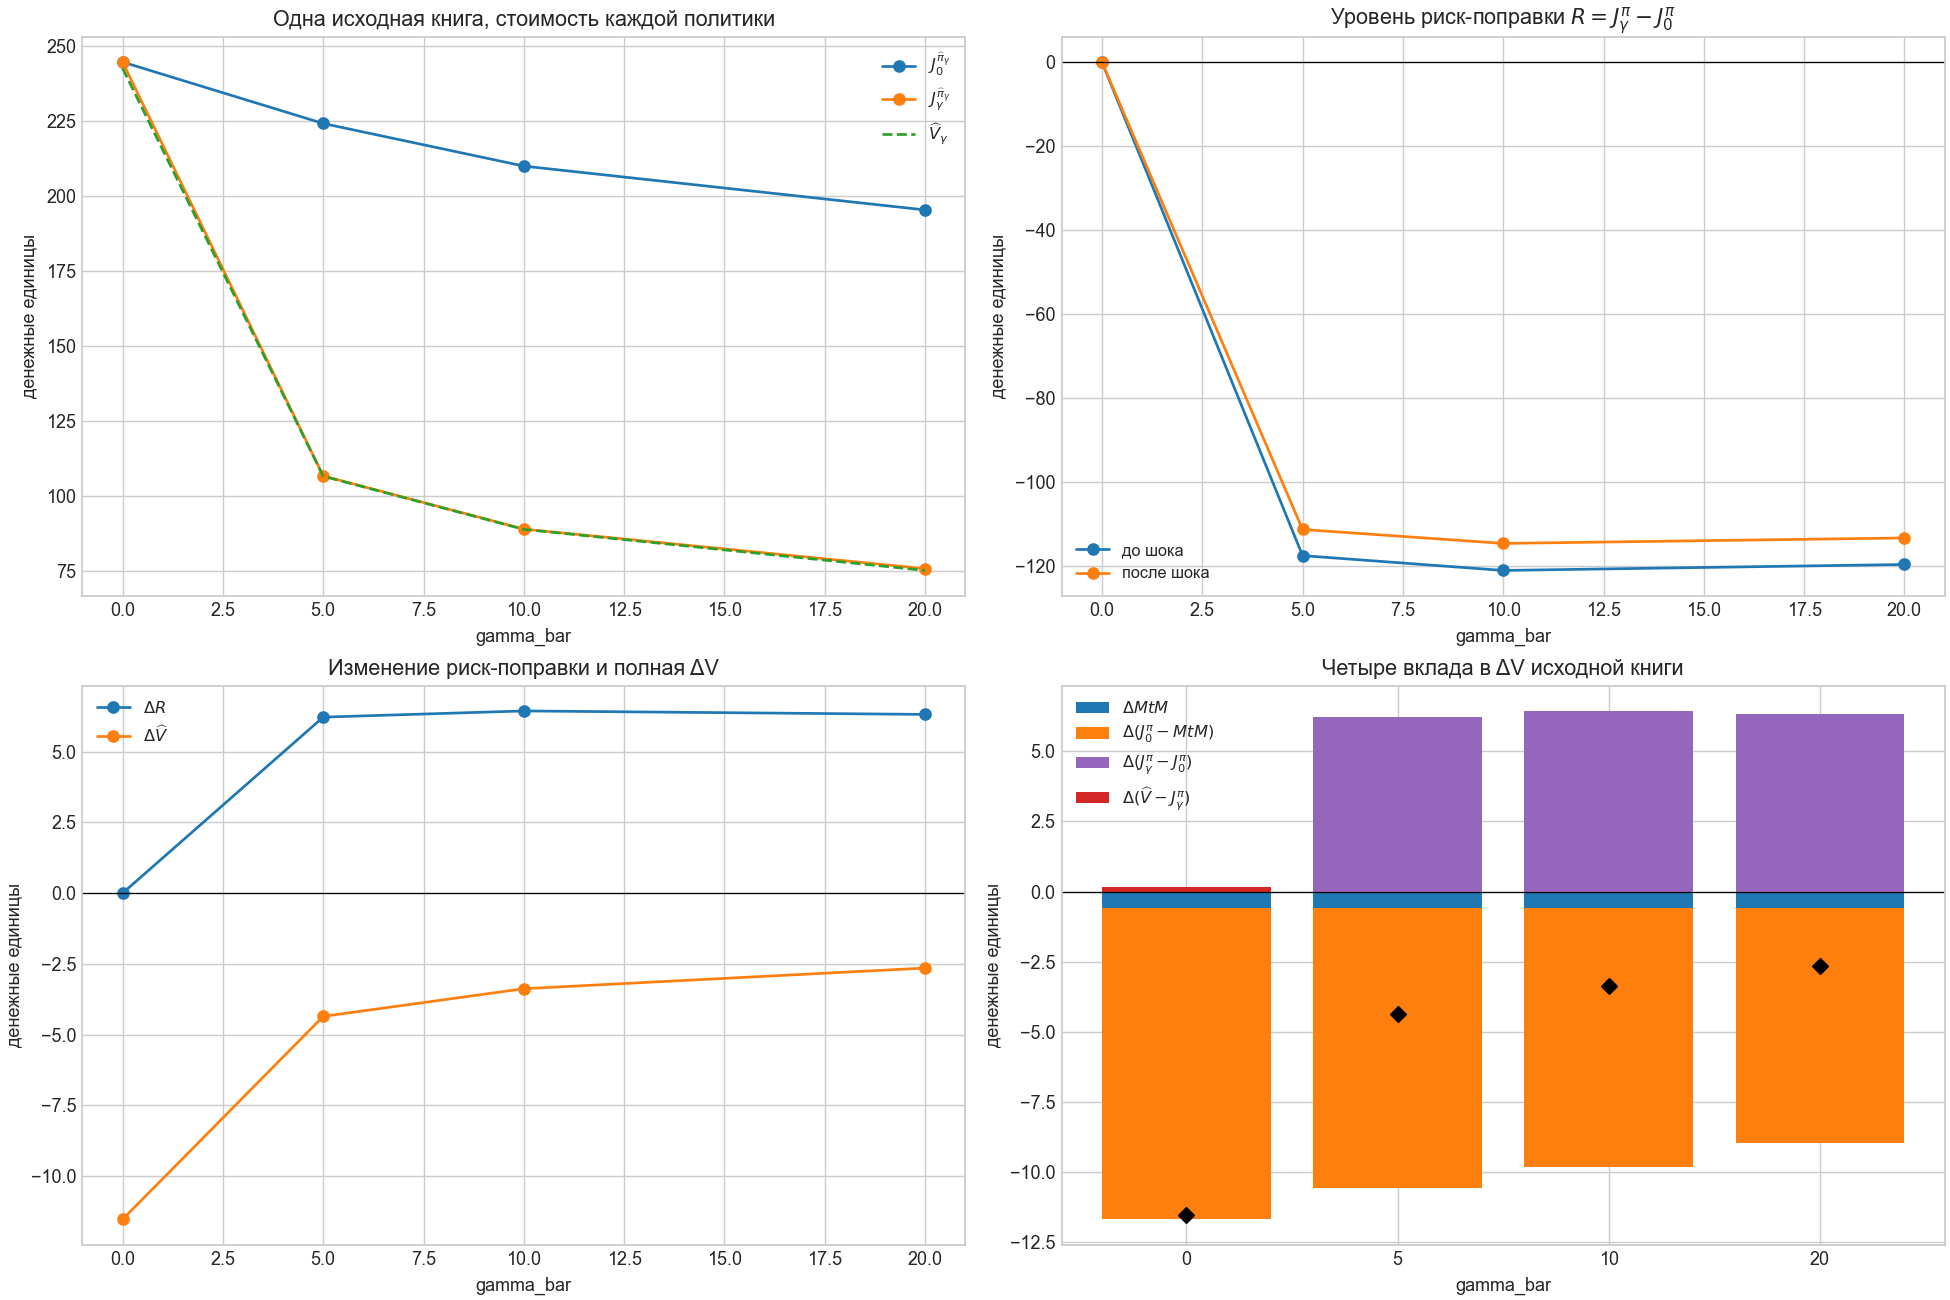

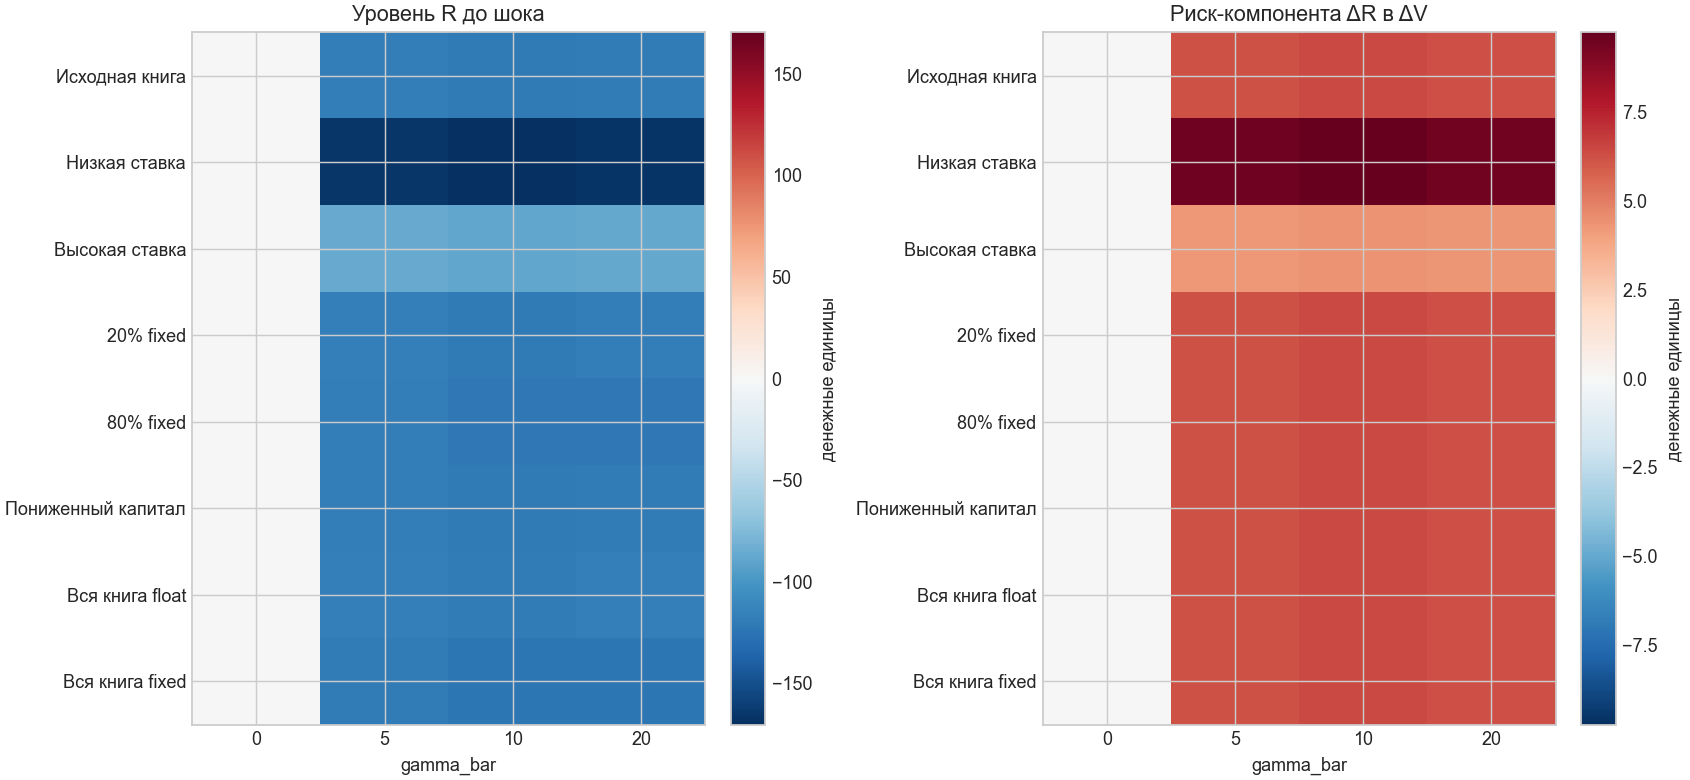

ВНИМАНИЕ: часть оценок не сошлась. Малый остаток сети не исключает систематическую ошибку двух J; точные величины вкладов пока не установлены.


In [9]:
if not evaluations:
    print('Первые графики готовы без новых обучений. Для разложения включите '
          'RUN_FULL_EVALUATION=True и выполните две последние ячейки.')
else:
    completed=[q for q in records if q['gamma'] in evaluations]
    eg=np.array([q['gamma'] for q in completed])
    parts=[];risks_base=[];risks_shock=[];j0_level=[];jg_level=[]
    for q in completed:
        zero,risk=evaluations[q['gamma']]
        j0=zero['anchors'].numpy();jg=risk['anchors'].numpy()
        d0=j0[N_SC:]-j0[:N_SC];dg=jg[N_SC:]-jg[:N_SC]
        rr=jg-j0
        component=np.column_stack((mtm_delta,d0-mtm_delta,dg-d0,q['delta_v']-dg))
        np.testing.assert_allclose(component.sum(1),q['delta_v'],atol=1e-8)
        parts.append(component)
        risks_base.append(rr[:N_SC]);risks_shock.append(rr[N_SC:])
        j0_level.append(j0[0]);jg_level.append(jg[0])
        for name,result in (('J0',zero),('Jgamma',risk)):
            last=result['diagnostics'][-1]
            print(f"gamma={q['gamma']:g} {name}: converged={result['converged']}, "
                  f"RMSE={last['rmse']:.5f}, anchor={last['anchor']:.5f}, drift={last['drift']:.5f}")
    parts=np.stack(parts);risks_base=np.stack(risks_base);risks_shock=np.stack(risks_shock)
    fig,axes=plt.subplots(2,2,figsize=(15,10),constrained_layout=True)
    axes[0,0].plot(eg,j0_level,'o-',label=r'$J_0^{\widehat\pi_\gamma}$')
    axes[0,0].plot(eg,jg_level,'o-',label=r'$J_\gamma^{\widehat\pi_\gamma}$')
    axes[0,0].plot(eg,[q['source_values'][0] for q in completed],'--',label=r'$\widehat V_\gamma$')
    axes[0,0].set(title='Одна исходная книга, стоимость каждой политики',ylabel='денежные единицы')
    axes[0,1].plot(eg,risks_base[:,0],'o-',label='до шока')
    axes[0,1].plot(eg,risks_shock[:,0],'o-',label='после шока')
    axes[0,1].axhline(0,color='black',lw=.7)
    axes[0,1].set(title=r'Уровень риск-поправки $R=J_\gamma^\pi-J_0^\pi$',ylabel='денежные единицы')
    axes[1,0].plot(eg,parts[:,0,2],'o-',label=r'$\Delta R$')
    axes[1,0].plot(eg,[q['delta_v'][0] for q in completed],'o-',label=r'$\Delta\widehat V$')
    axes[1,0].axhline(0,color='black',lw=.7)
    axes[1,0].set(title='Изменение риск-поправки и полная ΔV',ylabel='денежные единицы')
    positive=np.zeros(len(eg));negative=np.zeros(len(eg))
    labels=(r'$\Delta MtM$',r'$\Delta(J_0^\pi-MtM)$',
            r'$\Delta(J_\gamma^\pi-J_0^\pi)$',r'$\Delta(\widehat V-J_\gamma^\pi)$')
    xx=np.arange(len(eg))
    for j,(label,color) in enumerate(zip(labels,('tab:blue','tab:orange','tab:purple','tab:red'))):
        v=parts[:,0,j];bottom=np.where(v>=0,positive,negative)
        axes[1,1].bar(xx,v,bottom=bottom,label=label,color=color)
        positive+=np.maximum(v,0);negative+=np.minimum(v,0)
    axes[1,1].scatter(xx,[q['delta_v'][0] for q in completed],color='black',marker='D',zorder=4)
    axes[1,1].set(title='Четыре вклада в ΔV исходной книги',xticks=xx,
                  xticklabels=[f'{v:g}' for v in eg],ylabel='денежные единицы')
    axes[1,1].axhline(0,color='black',lw=.7)
    for ax in axes.flat:ax.set_xlabel('gamma_bar');ax.legend(fontsize=9)
    plt.show()
    fig,axes=plt.subplots(1,2,figsize=(13,6),constrained_layout=True)
    for ax,array,title in ((axes[0],risks_base,'Уровень R до шока'),
                           (axes[1],risks_shock-risks_base,'Риск-компонента ΔR в ΔV')):
        data=array.T
        lim=max(float(np.max(np.abs(data))),.001)
        im=ax.imshow(data,aspect='auto',cmap='RdBu_r',vmin=-lim,vmax=lim)
        ax.set(title=title,xticks=range(len(eg)),xticklabels=[f'{g:g}' for g in eg],
               yticks=range(N_SC),yticklabels=[s[0] for s in specs],xlabel='gamma_bar')
        fig.colorbar(im,ax=ax,label='денежные единицы')
    plt.show()
    if any(not result['converged'] for g in evaluations for result in evaluations[g]):
        print('ВНИМАНИЕ: часть оценок не сошлась. Малый остаток сети не исключает '
              'систематическую ошибку двух J; точные величины вкладов пока не установлены.')
    if np.max(risks_base)>EVAL_TOL or np.max(risks_shock)>EVAL_TOL:
        print('Нарушено ожидаемое R<=0: это численный диагностический сигнал, не доход от риска.')

## Как интерпретировать сравнение

* Денежная $\Delta V$ и относительная $\Delta V/V$ отвечают на разные вопросы. Меньшая денежная дельта при большой $\bar\gamma$ может сопровождать просто более низкий уровень $V$; проверяйте оба графика.
* В одном и том же состоянии $\Delta MtM$ одинакова для всех gamma: параметр предпочтений не входит в её формулу. Различия этой метрики при деятельности разных политик возникнут через созданные ими состояния.
* Уровень $R=J_\gamma^\pi-J_0^\pi$ и вклад $\Delta R$ в шоковую метрику различаются. Большой отрицательный уровень $R$ сам по себе не означает большого или отрицательного $\Delta R$.
* Средние выплаты и нижний дециль за 15 лет — описание конкретного конечного отрезка деятельности. Энтропийный рекурсивный критерий действует бессрочно; более риск-аверсивная политика не обязана улучшать каждый из этих показателей.
* Все оценки $J$ относятся к фиксированной сохранённой обратной связи. Их обучение не меняет исходные политики. Невязка оценки и остаток $\widehat V-J_\gamma^\pi$ должны рассматриваться вместе.


## Отдельный рисунок разложения по gamma для презентации

После полной оценки политик эта ячейка строит четыре вклада в $\Delta V$ исходного состояния при разных $\bar\gamma$. Все значения относятся к **одной и той же начальной книге** и одной eta. На графике печатаются eta и chi, чтобы не смешивать сетки. Точки — $\Delta\widehat V$, а не сумма абсолютных значений вкладов. Уровень $J_\gamma^\pi-J_0^\pi$ и его изменение при шоке — разные показатели; здесь используется именно изменение.

PNG и таблица с метаданными сохраняются в `gamma_interpretation_figures/` внутри папки sweep. В обычном режиме PNG также копируется в `stationary_formulation/figures/gamma_delta_v_components.png`, который использует новый слайд. Если нет рассчитанных $J_0,J_\gamma$, ячейка не рисует выдуманные компоненты: включите `RUN_FULL_EVALUATION=True` и выполните оценку выше. Данные старой сетки chi=0 подписываются как chi=0.

График: /private/tmp/irrbb_gamma_shock_slides/export/gamma_delta_v_components.png
ВНИМАНИЕ: есть несошедшиеся оценки; размеры вкладов предварительны.


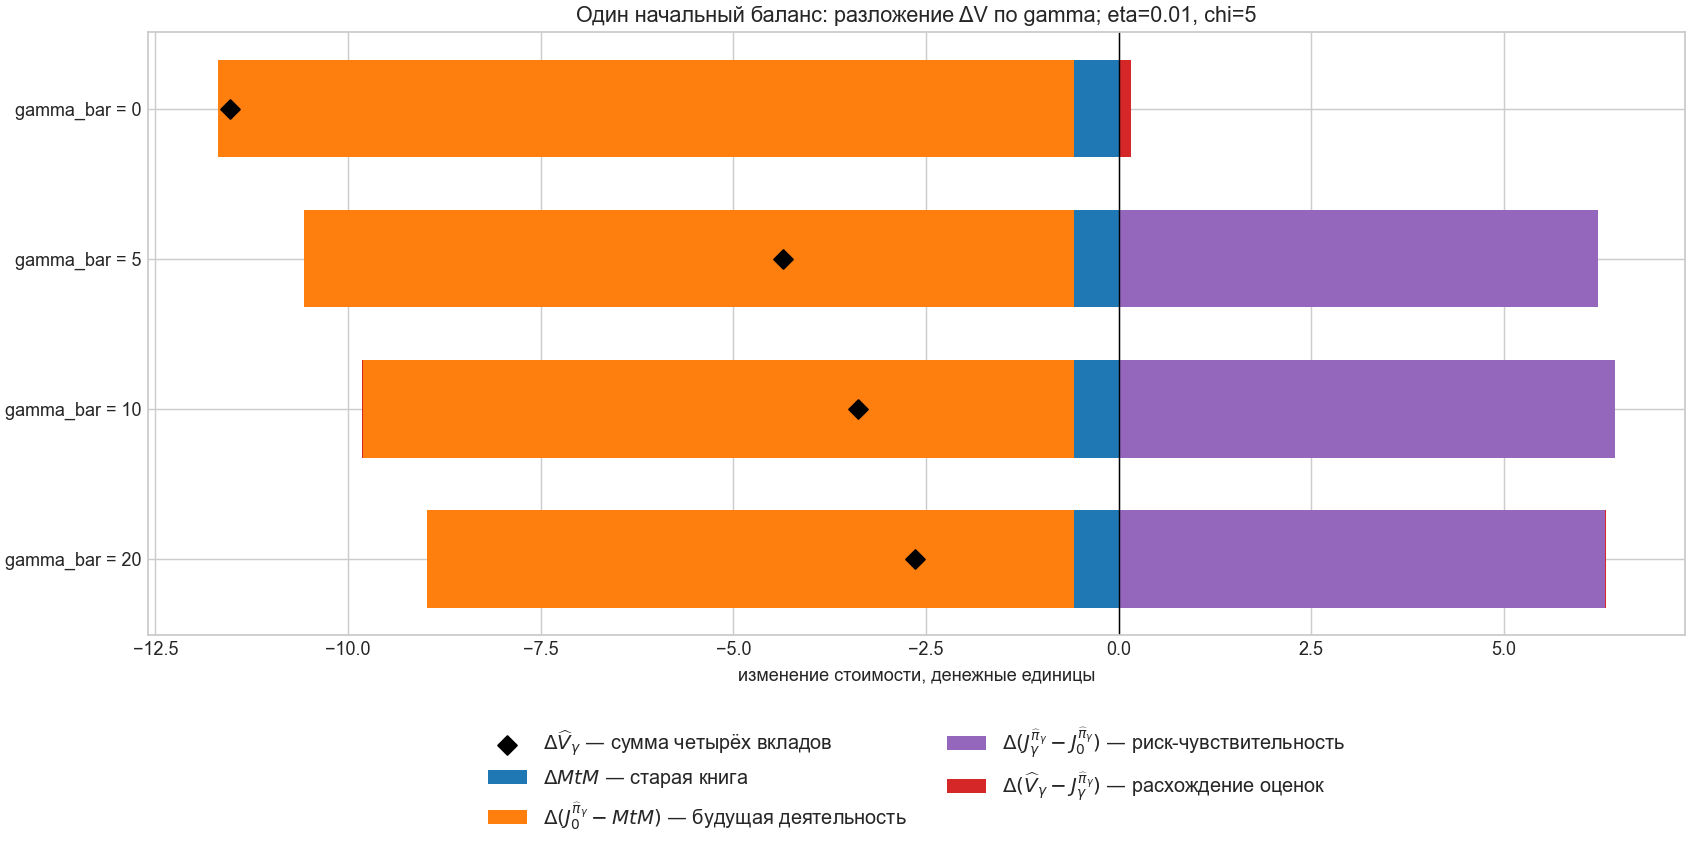

In [12]:
if not evaluations:
    print('Нет J0/Jgamma: график разложения по gamma пока не построен. '
          'Нужны оценки политик из предыдущего раздела.')
else:
    export_records=[q for q in records if q['gamma'] in evaluations]
    export_rows=[]
    for q in export_records:
        zero,risk=evaluations[q['gamma']]
        a=zero['anchors'].detach().cpu().numpy()
        b=risk['anchors'].detach().cpu().numpy()
        da=a[N_SC:]-a[:N_SC];db=b[N_SC:]-b[:N_SC]
        row=[float(mtm_delta[0]),float(da[0]-mtm_delta[0]),
             float(db[0]-da[0]),float(q['delta_v'][0]-db[0])]
        np.testing.assert_allclose(sum(row),q['delta_v'][0],atol=1e-8)
        export_rows.append({'gamma':q['gamma'],'components':row,'delta_v':float(q['delta_v'][0]),
                            'source_checkpoint':str(q['path']),
                            'J0_converged':zero['converged'],'Jgamma_converged':risk['converged'],
                            'J0_diagnostics':zero['diagnostics'][-1],
                            'Jgamma_diagnostics':risk['diagnostics'][-1]})
    export_dir=sweep_dir/'gamma_interpretation_figures' if not SMOKE else Path('/private/tmp/gamma_slide_smoke')
    export_dir.mkdir(parents=True,exist_ok=True)
    vals=np.array([row['components'] for row in export_rows])
    pos=np.arange(len(export_rows));positive=np.zeros(len(pos));negative=np.zeros(len(pos))
    fig,ax=plt.subplots(figsize=(13,6.5),constrained_layout=True)
    export_names=(r'$\Delta MtM$ — старая книга',
                  r'$\Delta(J_0^{\widehat\pi_\gamma}-MtM)$ — будущая деятельность',
                  r'$\Delta(J_\gamma^{\widehat\pi_\gamma}-J_0^{\widehat\pi_\gamma})$ — риск-чувствительность',
                  r'$\Delta(\widehat V_\gamma-J_\gamma^{\widehat\pi_\gamma})$ — расхождение оценок')
    for j,(name,color) in enumerate(zip(export_names,('tab:blue','tab:orange','tab:purple','tab:red'))):
        part=vals[:,j];left=np.where(part>=0,positive,negative)
        ax.barh(pos,part,left=left,label=name,color=color,height=.65)
        positive+=np.maximum(part,0);negative+=np.minimum(part,0)
    ax.scatter([row['delta_v'] for row in export_rows],pos,color='black',marker='D',s=55,
               zorder=5,label=r'$\Delta\widehat V_\gamma$ — сумма четырёх вкладов')
    ax.set(yticks=pos,yticklabels=[f"gamma_bar = {row['gamma']:g}" for row in export_rows],
           xlabel='изменение стоимости, денежные единицы',
           title=f'Один начальный баланс: разложение ΔV по gamma; eta={ETA:g}, chi={p.growth_rate_sensitivity:g}')
    ax.invert_yaxis();ax.axvline(0,color='black',lw=.8)
    ax.legend(loc='upper center',bbox_to_anchor=(.5,-.12),fontsize=11,ncol=2,frameon=False)
    figure_path=export_dir/'gamma_delta_v_components.png'
    fig.savefig(figure_path,dpi=170)
    metadata={'parameters':asdict(p),'eta':ETA,'reference_state':states[0].cpu().tolist(),
              'shock':SHOCK,'sweep_dir':str(sweep_dir),'rows':export_rows}
    (export_dir/'gamma_delta_v_components.json').write_text(json.dumps(metadata,ensure_ascii=False,indent=2))
    if not SMOKE:
        presentation_assets=root/'continuous_time_irrbb/risk_sensitive/stationary_formulation/figures'
        presentation_assets.mkdir(parents=True,exist_ok=True)
        (presentation_assets/'gamma_delta_v_components.png').write_bytes(figure_path.read_bytes())
        (presentation_assets/'gamma_delta_v_components.json').write_text(json.dumps(metadata,ensure_ascii=False,indent=2))
    print('График:',figure_path)
    if any(not row['J0_converged'] or not row['Jgamma_converged'] for row in export_rows):
        print('ВНИМАНИЕ: есть несошедшиеся оценки; размеры вкладов предварительны.')
    plt.show()